In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

#dataset na het opschonen van missing values inlezen
df = pd.read_csv('Leesmateriaal_DU.csv')
df = df.convert_dtypes()


In [9]:
# Vaste volgorde van de niveaus voor alle grafieken
niveau_volgorde = ["2F", "2F-3F", "3F", "3F+"]

# Teksten met onbekend niveau laten we weg bij vergelijkingen per niveau
bekend = df[df["Niveau"] != "Onbekend"]

Niveau               2F  2F-3F    3F   3F+
genre                                     
Fictie             43.9   45.6  42.6  44.5
Fictie / Roman     43.0   32.9  45.7  <NA>
Fictie / Thriller  41.6   46.4  44.6  <NA>
Informatief        44.4   54.4  55.7  52.9
Poëzie             53.4   59.0  50.3  60.3
Roman              38.0   <NA>  <NA>  45.4
Thriller           43.0   <NA>  52.2  <NA>


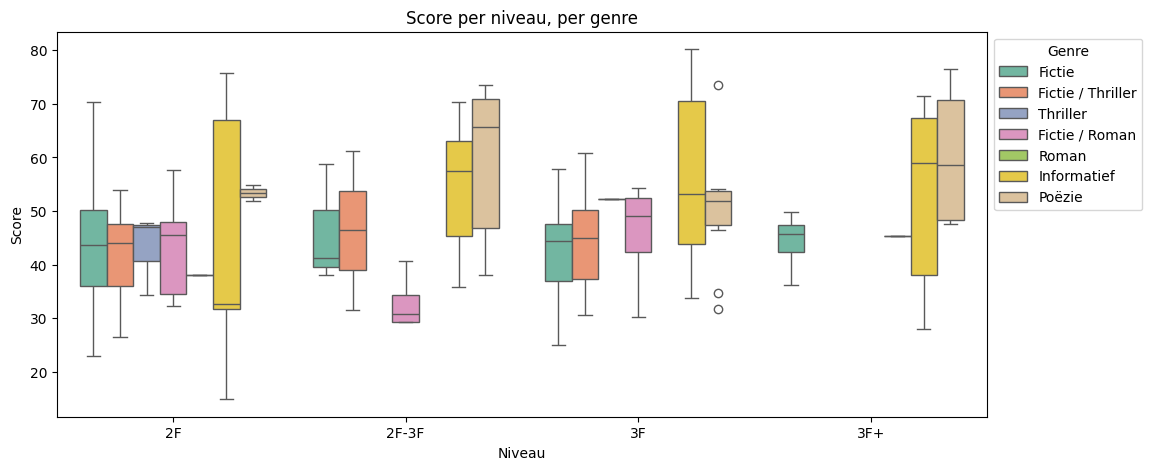

In [10]:
# Gemiddelde score per genre en niveau
gem = bekend.pivot_table(values="leescomplexiteit_score", index="genre", columns="Niveau", aggfunc="mean")[niveau_volgorde]
print(gem.round(1))

plt.figure(figsize=(12, 5))
sns.boxplot(data=bekend, x="Niveau", y="leescomplexiteit_score", hue="genre", order=niveau_volgorde,
            palette="Set2")
plt.title("Score per niveau, per genre")
plt.xlabel("Niveau")
plt.ylabel("Score")
plt.legend(title="Genre", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

Niveau                    2F  2F-3F  3F  3F+
genre             lengte                    
Fictie            middel  39      2  15    4
                  lang    42      3  21    6
Fictie / Roman    middel  12      2   3    0
                  lang     6      2   1    0
Fictie / Thriller middel   8      1   5    0
                  lang    12      1   6    0
Informatief       kort     5      5  18   11
Poëzie            middel   0      2   6    2
                  lang     2      3   4    2
Roman             middel   0      0   0    1
                  lang     1      0   0    0
Thriller          middel   2      0   0    0
                  lang     1      0   1    0
Combinaties in de tabel: 52 van de 36 mogelijke (3 genres x 3 lengtes x 4 niveaus)
Daarvan met minder dan 3 teksten: 31


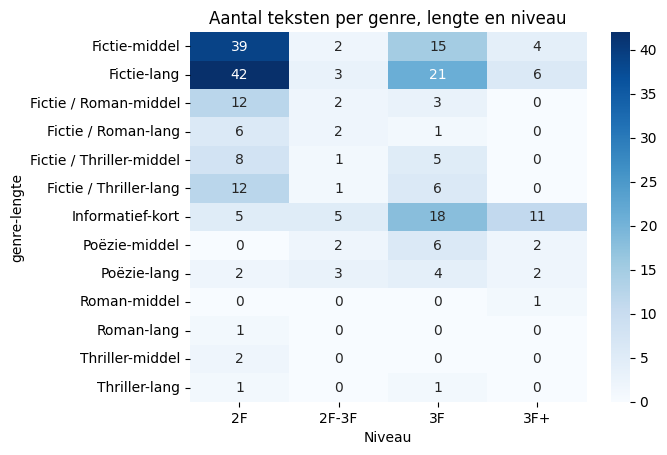

In [11]:
# Leestijd indelen in drie groepen
df["lengte"] = pd.cut(df["geschatte_leestijd_min"], bins=[0, 60, 400, 1000], labels=["kort", "middel", "lang"])
bekend = df[df["Niveau"] != "Onbekend"]

# Aantal teksten per combinatie van genre, lengte en niveau
aanbod = pd.crosstab([bekend["genre"], bekend["lengte"]], bekend["Niveau"])[niveau_volgorde]
print(aanbod)

# Combinaties in de tabel en hoeveel daarvan minder dan 3 teksten hebben
print("Combinaties in de tabel:", aanbod.size, "van de 36 mogelijke (3 genres x 3 lengtes x 4 niveaus)")
print("Daarvan met minder dan 3 teksten:", (aanbod < 3).sum().sum())

sns.heatmap(aanbod, annot=True, fmt="d", cmap="Blues")
plt.title("Aantal teksten per genre, lengte en niveau")
plt.show()